In [37]:
import os
import cv2
import json
import glob
import tiffslide
import numpy as np
import random
from shapely.geometry import shape, box, Polygon, MultiPolygon
from shapely.affinity import translate

# --- CONFIGURACIÓN ---data
RAW_DATA_DIR = os.path.join("/media/lci1/fac1e379-9201-42aa-80e8-b6775b0ab41b/JA/ratitas_2026")
WSI_IMAGES_DIR = os.path.join(RAW_DATA_DIR, "data/raw/wsi_images")
ANNOTATIONS_DIR = os.path.join(RAW_DATA_DIR, "data/processed/ANNOT_CLEAN-V4_w_nolabeled_now_background")
OUTPUT_DIR = os.path.join(RAW_DATA_DIR,"data/processed/YOLO-256x256-50ovlp_V4_")
METADATA_DIR = os.path.join(RAW_DATA_DIR,"data/raw/metadata")
os.makedirs(OUTPUT_DIR, exist_ok=True)


TILE_SIZE = 256
OVERLAP = 50
# Parámetros
TRAIN_RATIO = 0.7
VAL_RATIO = 0.2
TEST_RATIO = 0.1   # Asegurate que sumen 1
random.seed(42)


# Generación de tiles con categorias

In [38]:
images_excluded = ['slide_007', 'slide_008', 'slide_016', 'slide_018', 'slide_019', 'slide_025',
                    'slide_028', 'slide_029', 'slide_032', 'slide_034', 'slide_035', 'slide_041', 'slide_045', 
                    'slide_047', 'slide_048']





CLASS_MAP = {
    "Decidua": 0, "Decidual": 0, "dec": 0, "dec1": 0, "dec2": 0,
    "Labyrinth": 1, "lab": 1, "lab1": 1, "lab2": 1,
    "Junctional Zone": 2, "jz": 2, "Junctional": 2, 'no_labeled': 3#,'background':4
}

def get_yolo_segment_format(geometry, img_w, img_h):
    """Convierte geometría Shapely a string de puntos normalizados para YOLO-SEG."""
    results = []
    
    # Aseguramos que tratamos todo como una lista de geometrías
    if isinstance(geometry, Polygon):
        polys = [geometry]
    elif isinstance(geometry, MultiPolygon):
        polys = geometry.geoms
    else:
        # Si es una LineString o Point producto de la intersección, la ignoramos
        return results
    
    for poly in polys:
        # CORRECCIÓN AQUÍ: .is_empty (con punto y sin el 'inter' pegado)
        if poly.is_empty or not isinstance(poly, Polygon): 
            continue
            
        coords = np.array(poly.exterior.coords)
        
        # Normalizar (0 a 1)
        coords[:, 0] /= img_w
        coords[:, 1] /= img_h
        
        # YOLO necesita al menos 3 puntos para un polígono
        if len(coords) < 3: 
            continue
            
        # Aplanar y convertir a string
        flattened = coords.flatten().tolist()
        results.append(" ".join(map(str, flattened)))
        
    return results

# 1. Crear carpetas
for split in ['train', 'val', 'test']:
    os.makedirs(os.path.join(OUTPUT_DIR, "images", split), exist_ok=True)
    os.makedirs(os.path.join(OUTPUT_DIR, "labels", split), exist_ok=True)

# 2. Obtener imágenes
image_files = sorted(glob.glob(os.path.join(WSI_IMAGES_DIR, "*.tif")))
image_files = [
    f for f in image_files 
    if f.split('\\')[-1].replace('.tif','') not in images_excluded
]

random.shuffle(image_files)

# 3. Calcular índices
total = len(image_files)
train_end = int(total * TRAIN_RATIO)
val_end = train_end + int(total * VAL_RATIO)

train_files = set(image_files[:train_end])
val_files   = set(image_files[train_end:val_end])
test_files  = set(image_files[val_end:])

print(f"📂 Total: {total}")
print(f"Train: {len(train_files)} | Val: {len(val_files)} | Test: {len(test_files)}")

# 3. Bucle Principal

for img_path in image_files:
    try:
        base_name = os.path.basename(img_path).replace(".tif", "")
        geojson_path = os.path.join(ANNOTATIONS_DIR, f"{base_name}.geojson")
        current_split = "train" if img_path in train_files else "val"
        
        if not os.path.exists(geojson_path): continue

        print(f"🚜 Procesando {base_name} para {current_split}...")

        with tiffslide.TiffSlide(img_path) as slide:
            w, h = slide.dimensions
            full_img = np.array(slide.read_region((0,0), 0, (w, h)).convert("RGB"))
            full_img = cv2.cvtColor(full_img, cv2.COLOR_RGB2BGR)

        with open(geojson_path, 'r') as f:
            data = json.load(f)
            features = [
                {"geom": shape(f['geometry']), "class": f['properties'].get('name')}
                for f in data.get('features', [])
            ]

        count = 0
        for y in range(0, h - TILE_SIZE + 1, TILE_SIZE - OVERLAP):
            for x in range(0, w - TILE_SIZE + 1, TILE_SIZE - OVERLAP):
                tile_box = box(x, y, x + TILE_SIZE, y + TILE_SIZE)
                tile_labels = []

                for feat in features:
                    if tile_box.intersects(feat['geom']):
                        inter = feat['geom'].intersection(tile_box)
                        
                        # Ignorar si la intersección no tiene área (puntos o líneas sueltas)
                        if inter.is_empty or inter.area < 100: continue
                        
                        # Mover polígono al origen del parche
                        local_poly = translate(inter, xoff=-x, yoff=-y)
                        class_id = CLASS_MAP.get(feat['class'], -1)
                        
                        if class_id != -1:
                            yolo_segs = get_yolo_segment_format(local_poly, TILE_SIZE, TILE_SIZE)
                            for seg in yolo_segs:
                                tile_labels.append(f"{class_id} {seg}")

                if tile_labels:
                    tile_name = f"{base_name}_tile_{x}_{y}"
                    img_out = os.path.join(OUTPUT_DIR, "images", current_split, f"{tile_name}.jpg")
                    lbl_out = os.path.join(OUTPUT_DIR, "labels", current_split, f"{tile_name}.txt")
                    
                    cv2.imwrite(img_out, full_img[y:y+TILE_SIZE, x:x+TILE_SIZE])
                    with open(lbl_out, 'w') as f:
                        f.write("\n".join(tile_labels))
                    count += 1
    except Exception as e:
        print("Error en el slide: ",base_name, "Error: ", e)        
    print(f"✅ {base_name}: {count} parches creados.")

# 4. Crear archivo dataset.yaml
yaml_content = f"""
path: {os.path.abspath(OUTPUT_DIR)}
train: images/train
val: images/val

names:
  0: Decidua
  1: Labyrinth
  2: Junctional Zone
  3: no_labeled
  
"""
with open(os.path.join(OUTPUT_DIR, "dataset.yaml"), "w") as f:
    f.write(yaml_content)

print(f"\n🚀 Proceso terminado. Dataset listo en: {OUTPUT_DIR}")

📂 Total: 50
Train: 35 | Val: 10 | Test: 5
🚜 Procesando slide_037 para train...
✅ slide_037: 508 parches creados.
🚜 Procesando slide_033 para train...
✅ slide_033: 485 parches creados.
🚜 Procesando slide_026 para train...
✅ slide_026: 520 parches creados.
🚜 Procesando slide_014 para train...
✅ slide_014: 367 parches creados.
🚜 Procesando slide_005 para train...
✅ slide_005: 522 parches creados.
🚜 Procesando slide_061 para train...
Error en el slide:  slide_061 Error:  TopologyException: unable to assign free hole to a shell at 1690 5836
✅ slide_061: 912 parches creados.
🚜 Procesando slide_038 para train...
✅ slide_038: 403 parches creados.
🚜 Procesando slide_012 para train...
✅ slide_012: 500 parches creados.
🚜 Procesando slide_042 para train...
✅ slide_042: 616 parches creados.
🚜 Procesando slide_022 para train...
✅ slide_022: 621 parches creados.
🚜 Procesando slide_044 para train...
✅ slide_044: 464 parches creados.
🚜 Procesando slide_030 para train...
✅ slide_030: 531 parches creados

# Tiling con wsi_splitted

In [ ]:
import os
import cv2
import json
import glob
import tiffslide
import numpy as np
from shapely.geometry import shape, box, Polygon, MultiPolygon
from shapely.affinity import translate

# --- CONFIGURACIÓN ---
RAW_DATA_DIR = "/media/lci1/fac1e379-9201-42aa-80e8-b6775b0ab41b/JA/ratitas_2026"
WSI_SPLITTED_DIR = os.path.join(RAW_DATA_DIR, "data/raw/wsi_splitted")  # ← Carpeta con train/val/test
ANNOTATIONS_DIR = os.path.join(RAW_DATA_DIR, "data/raw/annotations_resized")
OUTPUT_DIR = os.path.join(RAW_DATA_DIR, "data/processed/YOLO-256x256-50ovlp")
METADATA_DIR = os.path.join(RAW_DATA_DIR, "data/raw/metadata")
os.makedirs(OUTPUT_DIR, exist_ok=True)

TILE_SIZE = 256
OVERLAP = 50

CLASS_MAP = {
    "Decidua": 0, "Decidual": 0, "dec": 0, "dec1": 0, "dec2": 0,
    "Labyrinth": 1, "lab": 1, "lab1": 1, "lab2": 1,
    "Junctional Zone": 2, "jz": 2, "Junctional": 2, 'no_labeled': 3,'background':4
}

def get_yolo_segment_format(geometry, img_w, img_h):
    """Convierte geometría Shapely a string de puntos normalizados para YOLO-SEG."""
    results = []
    
    if isinstance(geometry, Polygon):
        polys = [geometry]
    elif isinstance(geometry, MultiPolygon):
        polys = geometry.geoms
    else:
        return results
    
    for poly in polys:
        if poly.is_empty or not isinstance(poly, Polygon): 
            continue
            
        coords = np.array(poly.exterior.coords)
        coords[:, 0] /= img_w
        coords[:, 1] /= img_h
        
        if len(coords) < 3: 
            continue
            
        flattened = coords.flatten().tolist()
        results.append(" ".join(map(str, flattened)))
        
    return results

# 1. Crear carpetas de salida
for split in ['train', 'val', 'test']:
    os.makedirs(os.path.join(OUTPUT_DIR, "images", split), exist_ok=True)
    os.makedirs(os.path.join(OUTPUT_DIR, "labels", split), exist_ok=True)

# 2. Procesar cada split (train, val, test) desde wsi_splitted
for split in ['train', 'val', 'test']:
    split_dir = os.path.join(WSI_SPLITTED_DIR, split)
    
    if not os.path.exists(split_dir):
        print(f"⚠️  No existe carpeta {split_dir}, saltando...")
        continue
    
    # Obtener imágenes de este split
    image_files = sorted(glob.glob(os.path.join(split_dir, "*.tif")))
    
    print(f"\n📂 {split.upper()}: {len(image_files)} imágenes")
    
    # 3. Procesar cada imagen del split
    for img_path in image_files:
        base_name = os.path.basename(img_path).replace(".tif", "")
        geojson_path = os.path.join(ANNOTATIONS_DIR, f"{base_name}.geojson")
        
        if not os.path.exists(geojson_path):
            print(f"  ⚠️  No existe GeoJSON para {base_name}, saltando...")
            continue

        print(f"  🚜 Procesando {base_name}...")

        # Abrir imagen completa (la de wsi_splitted ya está recortada)
        with tiffslide.TiffSlide(img_path) as slide:
            w, h = slide.dimensions
            full_img = np.array(slide.read_region((0,0), 0, (w, h)).convert("RGB"))
            full_img = cv2.cvtColor(full_img, cv2.COLOR_RGB2BGR)

        # Cargar anotaciones
        with open(geojson_path, 'r') as f:
            data = json.load(f)
            features = [
                {"geom": shape(f['geometry']), "class": f['properties'].get('name')}
                for f in data.get('features', [])
            ]

        # 4. Crear tiles con overlap
        count = 0
        for y in range(0, h - TILE_SIZE + 1, TILE_SIZE - OVERLAP):
            for x in range(0, w - TILE_SIZE + 1, TILE_SIZE - OVERLAP):
                tile_box = box(x, y, x + TILE_SIZE, y + TILE_SIZE)
                tile_labels = []

                for feat in features:
                    if tile_box.intersects(feat['geom']):
                        inter = feat['geom'].intersection(tile_box)
                        
                        if inter.is_empty or inter.area < 100: 
                            continue
                        
                        # Mover polígono al origen del tile
                        local_poly = translate(inter, xoff=-x, yoff=-y)
                        class_id = CLASS_MAP.get(feat['class'], -1)
                        
                        if class_id != -1:
                            yolo_segs = get_yolo_segment_format(local_poly, TILE_SIZE, TILE_SIZE)
                            for seg in yolo_segs:
                                tile_labels.append(f"{class_id} {seg}")

                if tile_labels:
                    tile_name = f"{base_name}_tile_{x}_{y}"
                    img_out = os.path.join(OUTPUT_DIR, "images", split, f"{tile_name}.jpg")
                    lbl_out = os.path.join(OUTPUT_DIR, "labels", split, f"{tile_name}.txt")
                    
                    cv2.imwrite(img_out, full_img[y:y+TILE_SIZE, x:x+TILE_SIZE])
                    with open(lbl_out, 'w') as f:
                        f.write("\n".join(tile_labels))
                    count += 1

        print(f"    ✅ {count} tiles creados")

# 5. Crear archivo dataset.yaml
yaml_content = f"""
path: {os.path.abspath(OUTPUT_DIR)}
train: images/train
val: images/val
test: images/test

names:
  0: Decidua
  1: Labyrinth
  2: Junctional Zone
"""
with open(os.path.join(OUTPUT_DIR, "dataset.yaml"), "w") as f:
    f.write(yaml_content)

print(f"\n🚀 Proceso terminado. Dataset listo en: {OUTPUT_DIR}")


📂 TRAIN: 35 imágenes
  🚜 Procesando slide_001...
    ✅ 516 tiles creados
  🚜 Procesando slide_004...
    ✅ 473 tiles creados
  🚜 Procesando slide_005...
    ✅ 442 tiles creados
  🚜 Procesando slide_012...
    ✅ 443 tiles creados
  🚜 Procesando slide_013...
    ✅ 393 tiles creados
  🚜 Procesando slide_014...
    ✅ 301 tiles creados
  🚜 Procesando slide_015...
    ✅ 455 tiles creados
  🚜 Procesando slide_017...
    ✅ 513 tiles creados
  🚜 Procesando slide_022...
    ✅ 583 tiles creados
  🚜 Procesando slide_024...
    ✅ 520 tiles creados
  🚜 Procesando slide_026...
    ✅ 233 tiles creados
  🚜 Procesando slide_027...
    ✅ 241 tiles creados
  🚜 Procesando slide_030...
    ✅ 477 tiles creados
  🚜 Procesando slide_031...
    ✅ 537 tiles creados
  🚜 Procesando slide_033...
    ✅ 449 tiles creados
  🚜 Procesando slide_036...
    ✅ 485 tiles creados
  🚜 Procesando slide_037...
    ✅ 414 tiles creados
  🚜 Procesando slide_038...
    ✅ 390 tiles creados
  🚜 Procesando slide_040...
    ✅ 464 tile

# Generación de tiles de fondos_

In [8]:
import os
import glob
import json
import random
import cv2
import numpy as np
import tiffslide
from shapely.geometry import shape, box
from shapely.ops import unary_union

# --- CONFIGURACIÓN ---
RAW_DATA_DIR = os.path.join("/media/lci1/fac1e379-9201-42aa-80e8-b6775b0ab41b/JA/ratitas_2026")
WSI_IMAGES_DIR = os.path.join(RAW_DATA_DIR, "data/raw/wsi_images")
ANNOTATIONS_DIR = os.path.join(RAW_DATA_DIR, "data/raw/annotations_resized")
OUTPUT_DIR = os.path.join(RAW_DATA_DIR,"data/processed/YOLO-1280x1280-256ovlp_w_bgs")
METADATA_DIR = os.path.join(RAW_DATA_DIR,"data/raw/metadata")
os.makedirs(OUTPUT_DIR, exist_ok=True)
t = "train" # O "val", depende dónde quieras más fondos
v = 'val'
TILE_SIZE = 1280
NUM_BACKGROUND_TILES_PER_IMAGE = 5 # Cuántos fondos quieres por imagen grande

# 1. Crear carpetas si no existen
os.makedirs(os.path.join(OUTPUT_DIR, "images", t), exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "labels", t), exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "images", v), exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "labels", v), exist_ok=True)
image_files = glob.glob(os.path.join(WSI_IMAGES_DIR, "*.tif"))

for img_path in image_files:
    base_name = os.path.basename(img_path).replace(".tif", "")
    geojson_path = os.path.join(ANNOTATIONS_DIR, f"{base_name}.geojson")
    
    if not os.path.exists(geojson_path): continue
    
    print(f"🔍 Buscando fondos en {base_name}...")
    
    with tiffslide.TiffSlide(img_path) as slide:
        w, h = slide.dimensions
        
        # Cargar anotaciones para saber dónde NO hay tejido
        with open(geojson_path, 'r') as f:
            data = json.load(f)
            features = [shape(f['geometry']) for f in data.get('features', [])]
            
        if not features: continue
        all_labels_geom = unary_union(features)
        
        # 2. Bucle para generar fondos
        generated_backgrounds = 0
        attempts = 0
        
        while generated_backgrounds < NUM_BACKGROUND_TILES_PER_IMAGE and attempts < 50:
            attempts += 1
            
            # Punto aleatorio cualquiera en la imagen
            x = random.randint(0, w - TILE_SIZE)
            y = random.randint(0, h - TILE_SIZE)
            
            tile_box = box(x, y, x + TILE_SIZE, y + TILE_SIZE)
            
            # 3. VERIFICACIÓN: ¿El parche intersecta tejido?
            if not tile_box.intersects(all_labels_geom):
                # Es fondo puro!
                if random.random() < 0.8: # 80% probabilidad
                    target_split = "train"
                else:
                    target_split = "val"
                # Guardar imagen
                tile_name = f"{base_name}_back_{generated_backgrounds}"
                img_out = os.path.join(OUTPUT_DIR, "images", target_split, f"{tile_name}.jpg")
                lbl_out = os.path.join(OUTPUT_DIR, "labels", target_split, f"{tile_name}.txt")
                
                tile_img = slide.read_region((x, y), 0, (TILE_SIZE, TILE_SIZE)).convert("RGB")
                tile_img = cv2.cvtColor(np.array(tile_img), cv2.COLOR_RGB2BGR)
                
                cv2.imwrite(img_out, tile_img)
                
                # 4. GUARDAR LABEL VACÍO
                open(lbl_out, 'w').close() # Crea el archivo pero no escribe nada
                
                generated_backgrounds += 1
                print(f"✅ Fondo {generated_backgrounds} creado.")

print("🏁 Proceso de generación de fondos terminado.")

🔍 Buscando fondos en slide_037...
✅ Fondo 1 creado.
✅ Fondo 2 creado.
✅ Fondo 3 creado.
✅ Fondo 4 creado.
✅ Fondo 5 creado.
🔍 Buscando fondos en slide_001...
✅ Fondo 1 creado.
✅ Fondo 2 creado.
✅ Fondo 3 creado.
✅ Fondo 4 creado.
✅ Fondo 5 creado.
🔍 Buscando fondos en slide_029...
✅ Fondo 1 creado.
✅ Fondo 2 creado.
✅ Fondo 3 creado.
✅ Fondo 4 creado.
✅ Fondo 5 creado.
🔍 Buscando fondos en slide_051...
✅ Fondo 1 creado.
✅ Fondo 2 creado.
✅ Fondo 3 creado.
✅ Fondo 4 creado.
✅ Fondo 5 creado.
🔍 Buscando fondos en slide_053...
✅ Fondo 1 creado.
🔍 Buscando fondos en slide_025...
✅ Fondo 1 creado.
✅ Fondo 2 creado.
✅ Fondo 3 creado.
✅ Fondo 4 creado.
✅ Fondo 5 creado.
🔍 Buscando fondos en slide_018...
✅ Fondo 1 creado.
✅ Fondo 2 creado.
✅ Fondo 3 creado.
✅ Fondo 4 creado.
✅ Fondo 5 creado.
🔍 Buscando fondos en slide_065...
✅ Fondo 1 creado.
✅ Fondo 2 creado.
✅ Fondo 3 creado.
✅ Fondo 4 creado.
✅ Fondo 5 creado.
🔍 Buscando fondos en slide_035...
✅ Fondo 1 creado.
✅ Fondo 2 creado.
✅ Fondo 3 

# Verificacion de imagenes

In [9]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import os
import cv2
import json
import glob
import tiffslide
import numpy as np
import random
from shapely.geometry import shape, box, Polygon, MultiPolygon
from shapely.affinity import translate

/tmp/ipykernel_1284195/3386190386.py:38: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


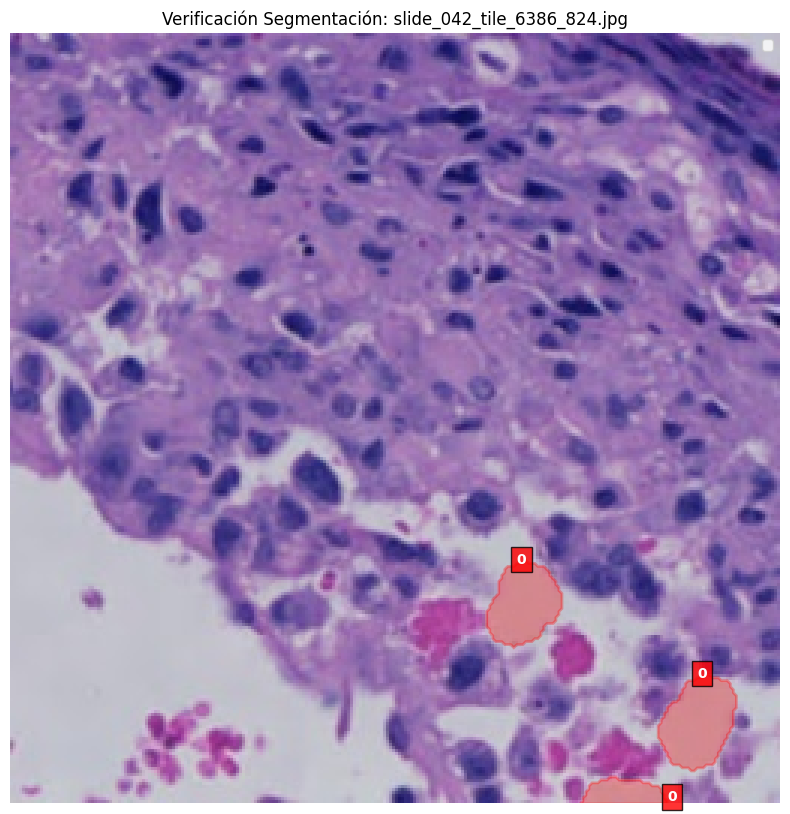

In [51]:


def verify_yolo_segmentation(img_path, label_path):
    # 1. Cargar la imagen del parche
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w, _ = img.shape
    
    fig, ax = plt.subplots(figsize=(10, 10))
    ax.imshow(img)
    
    # 2. Leer el archivo de labels (.txt)
    if os.path.exists(label_path):
        with open(label_path, 'r') as f:
            lines = f.readlines()
            
        for line in lines:
            data = list(map(float, line.split()))
            class_id = int(data[0])
            # Los puntos vienen en pares x, y normalizados
            points = np.array(data[1:]).reshape(-1, 2)
            
            # Desnormalizar puntos para dibujar sobre la imagen de 1024px
            points[:, 0] *= w
            points[:, 1] *= h
            
            # Crear el polígono para visualizar
            # Usamos un color distinto por clase (0: Rojo, 1: Verde, 2: Azul)
            colors = ['red', 'green', 'blue','yellow','purple']
            color = colors[class_id] if class_id < len(colors) else 'yellow'
            
            poly_patch = patches.Polygon(points, closed=True, linewidth=2, 
                                         edgecolor=color, facecolor=color, alpha=0.3)
            ax.add_patch(poly_patch)
            ax.text(points[0,0], points[0,1], str(class_id), color='white', 
                    fontweight='bold', bbox=dict(facecolor=color, alpha=0.8))

    plt.title(f"Verificación Segmentación: {os.path.basename(img_path)}")
    plt.axis('off')
    plt.legend()
    plt.show()

# --- PRUEBA CON UN PARCHE ALEATORIO ---
# Buscamos en la carpeta de train algún archivo generado
sample_images = glob.glob(os.path.join('/media/lci1/fac1e379-9201-42aa-80e8-b6775b0ab41b/JA/ratitas_2026/data/processed/YOLO-256x256-50ovlp_V4_', "images/train/*.jpg"))
if sample_images:
    ind = random.randint(0, len(sample_images) - 1)
    test_img = sample_images[ind]
    test_label = test_img.replace("images", "labels").replace(".jpg", ".txt")
    verify_yolo_segmentation(test_img, test_label)
else:
    print("❌ No se encontraron parches. Asegúrate de correr el script de tiling primero.")

# Mover tiles fondo a dataset original

In [6]:
import os
import shutil

# --- CONFIGURACIÓN ---
# La carpeta donde generaste los fondos nuevos
SOURCE_DIR = r"C:\Users\paez\Documents\Doct_2026\ratitas_2026\data\processed\yolo_dataset_1024x1024_bgs"
# La carpeta de tu dataset original donde están los parches con etiquetas
DEST_DIR = r"C:\Users\paez\Documents\Doct_2026\ratitas_2026\data\processed\yolo_dataset_1024x1024"

# --- ESTRUCTURA ---
subfolders = [
    os.path.join("images", "train"),
    os.path.join("images", "val"),
    os.path.join("labels", "train"),
    os.path.join("labels", "val")
]

# --- PROCESO DE MOVIMIENTO ---
for subfolder in subfolders:
    source_path = os.path.join(SOURCE_DIR, subfolder)
    dest_path = os.path.join(DEST_DIR, subfolder)
    
    # Verificar si la carpeta de origen existe
    if os.path.exists(source_path):
        print(f"📂 Moviendo archivos de: {source_path} a {dest_path}")
        
        # Asegurar que la carpeta de destino exista
        os.makedirs(dest_path, exist_ok=True)
        
        # Mover todos los archivos
        files = os.listdir(source_path)
        for file in files:
            #print(file)
            shutil.move(os.path.join(source_path, file), os.path.join(dest_path, file))
        
        print(f"✅ {len(files)} archivos movidos a {subfolder}.")
    else:
        print(f"⚠️ La carpeta de origen no existe: {source_path}")

print("\n🚀 Fusión de datasets completada.")

📂 Moviendo archivos de: C:\Users\paez\Documents\Doct_2026\ratitas_2026\data\processed\yolo_dataset_1024x1024_bgs\images\train a C:\Users\paez\Documents\Doct_2026\ratitas_2026\data\processed\yolo_dataset_1024x1024\images\train
✅ 253 archivos movidos a images\train.
📂 Moviendo archivos de: C:\Users\paez\Documents\Doct_2026\ratitas_2026\data\processed\yolo_dataset_1024x1024_bgs\images\val a C:\Users\paez\Documents\Doct_2026\ratitas_2026\data\processed\yolo_dataset_1024x1024\images\val
✅ 56 archivos movidos a images\val.
📂 Moviendo archivos de: C:\Users\paez\Documents\Doct_2026\ratitas_2026\data\processed\yolo_dataset_1024x1024_bgs\labels\train a C:\Users\paez\Documents\Doct_2026\ratitas_2026\data\processed\yolo_dataset_1024x1024\labels\train
✅ 253 archivos movidos a labels\train.
📂 Moviendo archivos de: C:\Users\paez\Documents\Doct_2026\ratitas_2026\data\processed\yolo_dataset_1024x1024_bgs\labels\val a C:\Users\paez\Documents\Doct_2026\ratitas_2026\data\processed\yolo_dataset_1024x1024\l